In [6]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [7]:
PROJECT_DIR = Path.cwd()

MODEL_PATH = Path.home() / ".files" / "models" / "yolo11n.pt"

DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "images"
VIDEO_DIR = DATASET_DIR

OUTPUT_DIR = PROJECT_DIR / "runs" / "person_detection"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Directory:", PROJECT_DIR)
print("Model Path:", MODEL_PATH)
print("Image Directory:", IMAGE_DIR)
print("Output Directory:", OUTPUT_DIR)

Project Directory: /Users/startup/projects/yolotest
Model Path: /Users/startup/.files/models/yolo11n.pt
Image Directory: /Users/startup/projects/yolotest/dataset/images
Output Directory: /Users/startup/projects/yolotest/runs/person_detection


In [8]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

model = YOLO(str(MODEL_PATH))

print("YOLO11n model loaded successfully!")

YOLO11n model loaded successfully!


In [9]:
CONFIDENCE_THRESHOLD = 0.25
IMAGE_SIZE = 640
PERSON_CLASS_ID = 0
DEVICE = "cpu"

In [10]:
image_path = IMAGE_DIR / "construction_worker.jpg"

if not image_path.exists():
    raise FileNotFoundError(f"Image not found: {image_path}")

print("Input Image:", image_path)

Input Image: /Users/startup/projects/yolotest/dataset/images/construction_worker.jpg


In [11]:
results = model.predict(
    source=str(image_path),
    classes=[PERSON_CLASS_ID],
    conf=CONFIDENCE_THRESHOLD,
    imgsz=IMAGE_SIZE,
    device=DEVICE
)

print("Person detection completed!")


image 1/1 /Users/startup/projects/yolotest/dataset/images/construction_worker.jpg: 640x608 1 person, 189.6ms
Speed: 18.3ms preprocess, 189.6ms inference, 12.2ms postprocess per image at shape (1, 3, 640, 608)
Person detection completed!


In [12]:
for result in results:
    for index, box in enumerate(result.boxes):

        x1, y1, x2, y2 = box.xyxy[0].tolist()

        width = x2 - x1
        height = y2 - y1

        center_x = (x1 + x2) / 2
        center_y = (y1 + y2) / 2

        confidence = box.conf[0].item()
        class_id = int(box.cls[0].item())

        print(f"Person {index + 1}")
        print(f"Class ID: {class_id}")
        print(f"Confidence: {confidence:.4f}")
        print(f"X1: {x1:.2f}, Y1: {y1:.2f}")
        print(f"X2: {x2:.2f}, Y2: {y2:.2f}")
        print(f"Width: {width:.2f}")
        print(f"Height: {height:.2f}")
        print(f"Center X: {center_x:.2f}")
        print(f"Center Y: {center_y:.2f}")
        print("-" * 40)

Person 1
Class ID: 0
Confidence: 0.8657
X1: 45.33, Y1: 28.13
X2: 443.42, Y2: 493.94
Width: 398.08
Height: 465.81
Center X: 244.38
Center Y: 261.03
----------------------------------------


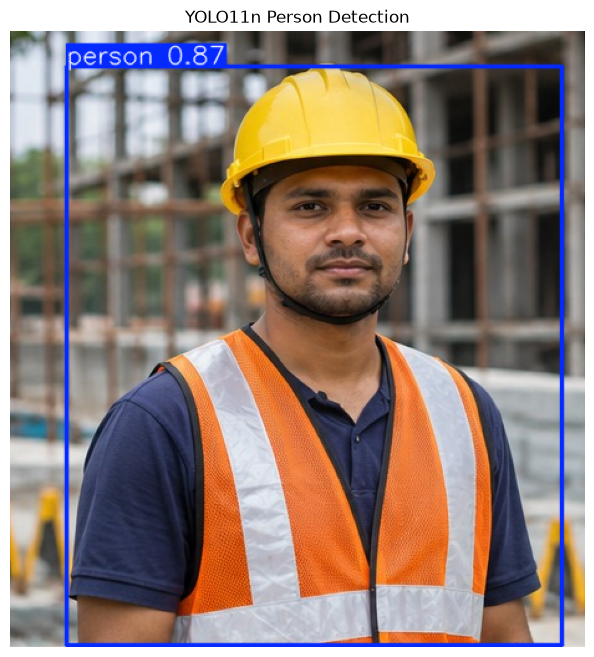

In [13]:
result_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("YOLO11n Person Detection")
plt.show()

In [14]:
output_path = OUTPUT_DIR / image_path.name

cv2.imwrite(str(output_path), result_image)

print("Detection output saved:", output_path)

Detection output saved: /Users/startup/projects/yolotest/runs/person_detection/construction_worker.jpg
